# UTS Graf Sains Data
Rekomendasi item-item Retail Rocket dengan Neo4j dan Python driver.

Bagus Febriansyah Pratama / 23031554144

Kode ada di folder `src/`. Notebook ini memanggil fungsinya dan menulis jawaban tiap soal.

In [1]:
import pandas as pd
import numpy as np
from neo4j import GraphDatabase

import src.config as config
import src.explore as explore
import src.prep as prep
import src.tutorial as tutorial
import src.vsm as vsm
import src.recommend as recommend
import src.similarity as similarity
from src.db import get_driver, import_events, reset_db

## 0 | Config
Periode yang sudah di set oleh Dosen (UTC, tanggal akhir ikut dihitung): P1 (train) 2015-05-25 sampai 2015-07-25, P2 (test) 2015-08-03 sampai 2015-08-18. Bobot event: view 1, addtocart 2, transaction 3. Seed 42.

In [2]:
print("P1 :", config.P1)
print("P2 :", config.P2)
print("bobot :", config.WEIGHTS)
print("seed :", config.SEED)

P1 : ('2015-05-25', '2015-07-25')
P2 : ('2015-08-03', '2015-08-18')
bobot : {'view': 1, 'addtocart': 2, 'transaction': 3}
seed : 42


## 1 | Tutorial driver (soal 1.2)
`add_friend` memakai `MERGE`, jadi dijalankan berulang tidak membuat simpul atau relasi ganda.

In [3]:
with GraphDatabase.driver(config.URI, auth=(config.USER, config.PASSWORD)) as drv:
    tutorial.add_friend(drv, "Arthur", "Guinevere")
    tutorial.add_friend(drv, "Arthur", "Lancelot")
    tutorial.add_friend(drv, "Arthur", "Merlin")
    tutorial.print_friends(drv, "Arthur")

Guinevere
Lancelot
Merlin


**Jawaban checkpoint**
1. Database yang dipakai: `neo4j` (default), dikirim lewat argumen `database_` pada `execute_query`.
2. Database lain: ganti `database_="nama_db"` di driver, atau awali query dengan `USE nama_db`. Daftar: `SHOW DATABASES`. Buat: `CREATE DATABASE nama_db`.
3. Graf berarah (directed), property graph. Simpul berlabel `Person`, relasi `KNOWS` dari Arthur ke tiap teman, tanpa bobot. Bentuknya bintang dengan Arthur di tengah.

Node tutorial dihapus supaya tidak tercampur dengan graf Retail Rocket.

In [4]:
with GraphDatabase.driver(config.URI, auth=(config.USER, config.PASSWORD)) as drv:
    tutorial.clear_demo(drv)

## 2 | Load dan filter periode (2.1 no. 1 dan 2)
`timestamp` berupa epoch **milidetik**. Batas awal inklusif, batas akhir diganti awal hari berikutnya (eksklusif) supaya tanggal terakhir penuh. File dibaca per chunk 500 ribu baris.

In [5]:
lo, hi = prep.date_range()
print("data dari", lo, "sampai", hi)

data dari 2015-05-03 03:00:04.384000+00:00 sampai 2015-09-18 02:59:47.788000+00:00


In [6]:
counts = prep.build_periods()
counts

{'P1': 1303835, 'P2': 290931}

In [7]:
sum_p1 = prep.summary(config.P1_CSV)
sum_p2 = prep.summary(config.P2_CSV)
pd.DataFrame({"P1 (train)": sum_p1, "P2 (test)": sum_p2})

,P1 (train),P2 (test)
rows,1303835,290931
visitors,674225,167495
items,170976,80323
events,"{'view': 1260787, 'addtocart': 32361, 'transac...","{'view': 280703, 'addtocart': 7833, 'transacti..."


**Jawaban**
- Rentang `events.csv`: 2015-05-03 sampai 2015-09-18, jadi kedua periode tercakup.
- P1: 1.303.835 baris, 674.225 visitor, 170.976 item. P2: 290.931 baris, 167.495 visitor, 80.323 item.
- Event P1: view 1.260.787, addtocart 32.361, transaction 10.687. Event P2: view 280.703, addtocart 7.833, transaction 2.395.

**Insight:** sekitar 96,5% event adalah view. Kunci jawaban (addtocart dan transaction P2) hanya 10.228 baris (3,5% dari P2), jadi tidak semua user bisa diuji.

## 3 | Import dan komposisi subgraph (2.1 no. 3)
Hanya P1 masuk ke Neo4j. Model: `(Visitor)-[:VIEWED|:ADDED_TO_CART|:BOUGHT]->(Item)`. Simpul dengan `MERGE` (unik lewat constraint), relasi dengan `CREATE` (satu event satu relasi).

In [8]:
driver = get_driver()
reset_db(driver)
done = import_events(driver, config.P1_CSV)
print("baris diimpor:", done)

impor batch: 100%|██████████| 261/261 [02:02<00:00,  2.12it/s]

baris diimpor: 1303835


Query komposisi:
```cypher
MATCH (n) RETURN labels(n)[0] AS label, count(n) AS total ORDER BY total DESC

MATCH ()-[r]->() RETURN type(r) AS relation, count(r) AS total ORDER BY total DESC
```

In [9]:
nodes = explore.node_composition(driver)
nodes

,label,total
0,Visitor,674225
1,Item,170976


In [10]:
rels = explore.rel_composition(driver)
rels

,relation,total
0,VIEWED,1260787
1,ADDED_TO_CART,32361
2,BOUGHT,10687


In [11]:
print(rels["total"].sum(), "relasi vs", sum_p1["rows"], "baris csv")

1303835 relasi vs 1303835 baris csv


**Jawaban**
- Simpul: `Visitor` 674.225, `Item` 170.976. Sama dengan jumlah unik di csv P1.
- Relasi: `VIEWED` 1.260.787, `ADDED_TO_CART` 32.361, `BOUGHT` 10.687. Total 1.303.835, sama dengan jumlah baris csv.

**Insight:** grafnya bipartit berarah (relasi hanya Visitor ke Item), jadi kemiripan harus dibuat lewat proyeksi.

## 4 | VSM user dan item (2.1 no. 4 dan 5)
Matriks X (baris user, kolom item) berisi jumlah bobot event per pasangan, disimpan sebagai `csr_matrix`. Vektor user = satu baris X, vektor item = satu kolom X.
```cypher
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item,
       sum(CASE type(r) WHEN 'VIEWED' THEN $w_view
                        WHEN 'ADDED_TO_CART' THEN $w_cart ELSE $w_buy END) AS weight
```

In [12]:
df = vsm.fetch_interactions(driver)
x, users, items = vsm.build_matrix(df)
print("pasangan visitor-item:", len(df))
print("shape X (user x item):", x.shape)

pasangan visitor-item: 1014275
shape X (user x item): (674225, 170976)


In [13]:
vsm.describe_both(x)

,vsm,shape,dimensi,nnz,sparsity_%,ukuran_mb,rata_nnz_per_vektor,maks_nnz_per_vektor
0,user (baris),674225 x 170976,170976,1014275,99.9991,10.81,1.50,2253
1,item (kolom),170976 x 674225,674225,1014275,99.9991,8.80,5.93,1623


Plot sampel 25 simpul paling aktif. Dua simpul terhubung kalau cosine minimal 0,15.

**VSM user**

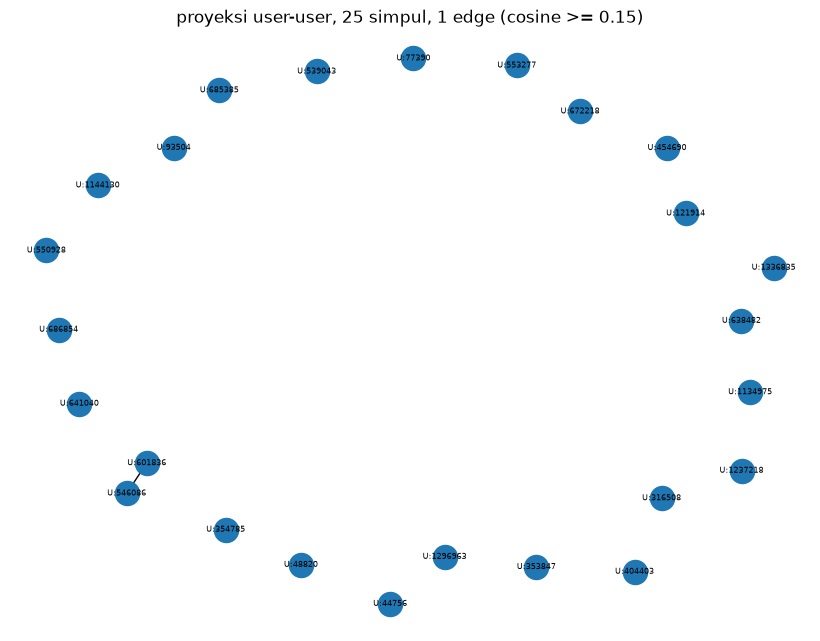

In [14]:
g_user = vsm.plot_sample(x, users, "user")

**VSM item**

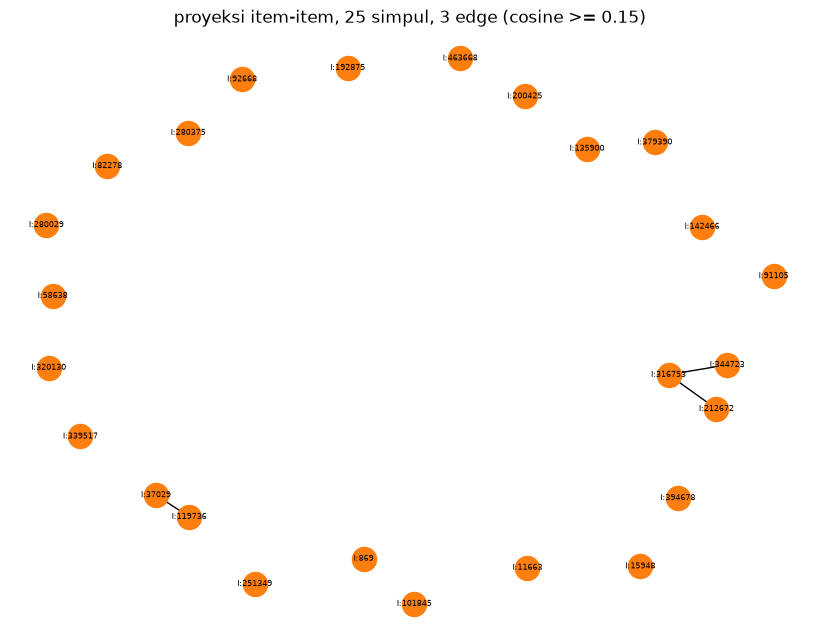

In [15]:
g_item = vsm.plot_sample(x, items, "item")

**Jawaban**
- X berukuran 674.225 x 170.976 dengan 1.014.275 sel terisi, sparsity 99,9991%.
- Vektor user: dimensi 170.976, rata-rata 1,50 sel terisi, maksimum 2.253.
- Vektor item: dimensi 674.225, rata-rata 5,93 sel terisi, maksimum 1.623.

**Insight:** kebanyakan user hanya menyentuh 1 sampai 2 item, vektornya sangat pendek. Vektor item rata-rata hampir 4 kali lebih panjang. Di plot sampel, user-user hanya 1 edge dan item-item 3 edge.

## 5 | Perbandingan proyeksi (2.1 no. 6)
Proyeksi user-user dan item-item dibandingkan dari jumlah simpul, ukuran matriks penuh, dan batas atas edge (tiap user dengan `d` item menyumbang `d(d-1)/2` pasangan item).

In [16]:
cost = vsm.projection_cost(x)
cost

,proyeksi,jumlah_simpul,ukuran_matriks_penuh,memori_penuh_gb_float32,batas_atas_edge
0,user-user,674225,674225 x 674225,1818.32,22577628
1,item-item,170976,170976 x 170976,116.93,12753889


**Jawaban**

| | user-user | item-item |
|---|---|---|
| simpul | 674.225 | 170.976 |
| matriks penuh (float32) | 1.818 GB | 117 GB |
| batas atas edge | 22.577.628 | 12.753.889 |

**Kesimpulan:** item-item dipilih. Lebih efisien (matriks sekitar 15 kali lebih kecil, edge lebih sedikit) dan lebih efektif (vektor lebih panjang, cosine lebih bermakna). Katalog item juga relatif tetap, sedangkan visitor terus berganti.

## 6 | Similarity item-item (2.1 no. 7)
Cosine antar vektor item: `cos(a,b) = (a . b) / (||a|| ||b||)`.
1. `item_matrix`: X di-transpose, item dengan kurang dari 3 visitor dinolkan.
2. `topk_cosine`: baris dinormalkan, cosine = perkalian titik, per 256 item, simpan 10 tetangga terdekat.
3. `pick_reference_item`: item acuan diacak (seed 42) dari 200 item paling aktif.

In [17]:
xi = similarity.item_matrix(x)
deg_i = np.diff(xi.indptr)
print("item total    :", xi.shape[0])
print("item dihitung :", int((deg_i > 0).sum()), f"(minimal {config.MIN_ITEM_USERS} visitor)")

item total    : 170976
item dihitung : 72941 (minimal 3 visitor)


In [18]:
idx, sim = similarity.topk_cosine(xi)
print("shape idx dan sim:", idx.shape, sim.shape)

cosine item-item: 100%|██████████| 668/668 [03:30<00:00,  3.17it/s]

shape idx dan sim: (170976, 10) (170976, 10)


In [19]:
ref = similarity.pick_reference_item(xi, items)
top5 = similarity.top_for_item(ref, items, idx, sim)
print("item acuan:", ref)
top5

item acuan: 161623


,item,score
0,455937,0.239906
1,43322,0.238118
2,372394,0.231114
3,155400,0.227844
4,374271,0.226433


**7a. Lima item paling mirip**, dan query Cypher untuk mengambilnya dari graf:
```cypher
MATCH (i:Item {itemId: $item})-[s:SIMILAR_TO]->(j:Item)
RETURN j.itemId AS item, s.score AS score ORDER BY s.score DESC LIMIT 5
```
Cek dengan numpy biasa:

In [20]:
a = xi[int(np.where(items == ref)[0][0])].toarray().ravel()
nb1 = int(top5["item"].iloc[0])
b = xi[int(np.where(items == nb1)[0][0])].toarray().ravel()
cek = float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))
print("cosine manual :", round(cek, 6))
print("cosine tabel  :", top5["score"].iloc[0])

cosine manual : 0.239906
cosine tabel  : 0.2399059683084488


**7b. Tulis balik ke graf** (relasi `SIMILAR_TO` dengan properti `score`, arah dari item ke tetangga top-k-nya):
```cypher
UNWIND $rows AS row
MATCH (a:Item {itemId: row.a})
MATCH (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score
```

In [21]:
similarity.delete_similar(driver)
before_cnt = explore.count_similar(driver)
before_edges = explore.neighborhood_before(driver, ref)
print("SIMILAR_TO sebelum:", before_cnt)

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL () { ... }', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'CALL { MATCH ()-[s:SIMILAR_TO]->() DELETE s } IN TRANSACTIONS OF 10000 ROWS'


SIMILAR_TO sebelum: 0


In [22]:
n_written = similarity.write_similar(driver, items, idx, sim)
print("relasi ditulis    :", n_written)
print("SIMILAR_TO sesudah:", explore.count_similar(driver))

tulis SIMILAR_TO: 100%|██████████| 85/85 [00:44<00:00,  1.89it/s]

relasi ditulis    : 423423
SIMILAR_TO sesudah: 423423


In [23]:
graph_top5 = similarity.top_from_graph(driver, ref)
same = len(graph_top5) == len(top5) and np.allclose(graph_top5["score"], top5["score"], atol=1e-5)
print("sama dengan hasil Python:", same)
graph_top5

sama dengan hasil Python: True


,item,score
0,455937,0.239906
1,43322,0.238118
2,372394,0.231114
3,155400,0.227844
4,374271,0.226433


**Jawaban**
- Item yang dihitung: 72.941 dari 170.976 (minimal 3 visitor).
- Item acuan 161623. Top-5: 455937 (0,2399), 43322 (0,2381), 372394 (0,2311), 155400 (0,2278), 374271 (0,2264).
- Cosine manual 0,239906 sama dengan tabel. Hasil Cypher dari graf sama dengan hasil Python.
- Relasi `SIMILAR_TO` ditulis: 423.423.

**Insight:** kemiripan tertinggi hanya sekitar 0,24, jadi sinyalnya lemah. Wajar karena tiap item rata-rata disentuh sedikit visitor.

## 7 | Sebelum dan sesudah similarity (2.1 no. 8)
Sebelum: hanya relasi visitor ke item. Sesudah: ditambah `SIMILAR_TO` dari item acuan.
```cypher
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: $item})
RETURN v.visitorId AS source, type(r) AS rel, i.itemId AS target LIMIT $limit

MATCH (i:Item {itemId: $item})-[s:SIMILAR_TO]->(j:Item)
RETURN i.itemId AS source, type(s) AS rel, j.itemId AS target, s.score AS score
```

In [24]:
vis_edges, sim_edges = explore.neighborhood_after(driver, ref)
print("SIMILAR_TO sebelum:", before_cnt, "| sesudah:", explore.count_similar(driver))
sim_edges

SIMILAR_TO sebelum: 0 | sesudah: 423423


,source,rel,target,score
0,161623,SIMILAR_TO,455937,0.239906
1,161623,SIMILAR_TO,43322,0.238118
2,161623,SIMILAR_TO,372394,0.231114
3,161623,SIMILAR_TO,155400,0.227844
4,161623,SIMILAR_TO,374271,0.226433
5,161623,SIMILAR_TO,545,0.225507
6,161623,SIMILAR_TO,325765,0.219446
7,161623,SIMILAR_TO,385148,0.209348
8,161623,SIMILAR_TO,384603,0.207992
9,161623,SIMILAR_TO,382191,0.204817


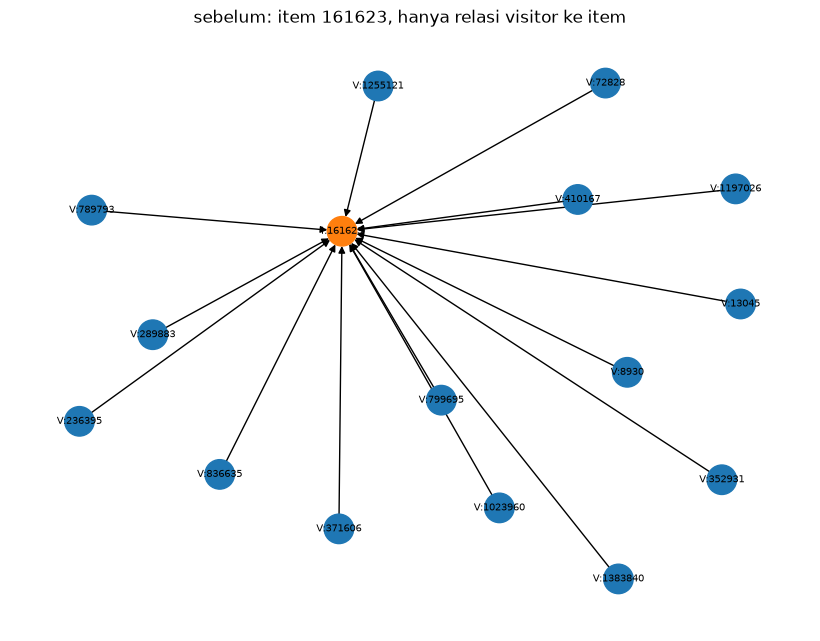

In [25]:
explore.plot_edges(before_edges, f"sebelum: item {ref}, hanya relasi visitor ke item")

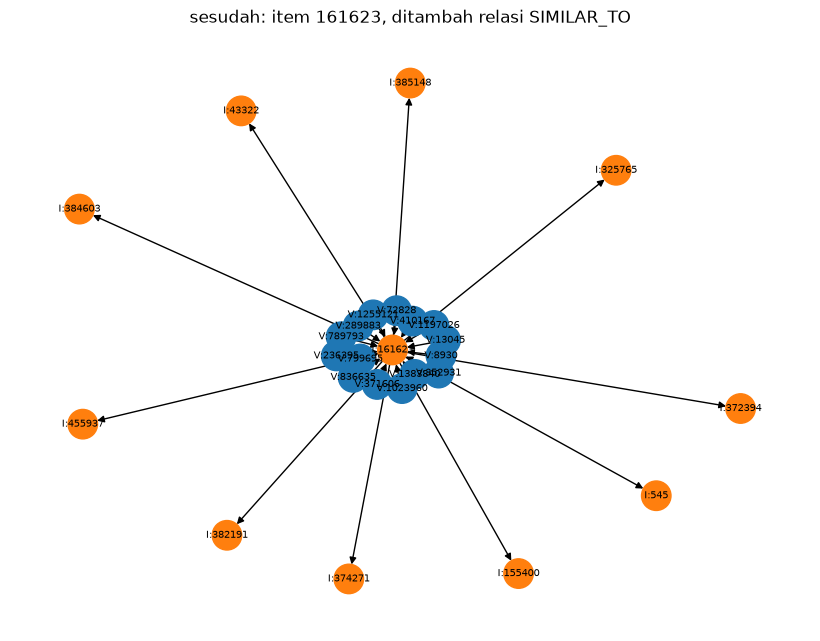

In [26]:
after_edges = pd.concat([vis_edges, sim_edges], ignore_index=True)
explore.plot_edges(after_edges, f"sesudah: item {ref}, ditambah relasi SIMILAR_TO")

**Jawaban**
- `SIMILAR_TO` sebelum 0, sesudah 423.423.
- Item acuan 161623 sekarang terhubung langsung ke 10 item lain.

**Insight:** sebelum similarity, dua item hanya terhubung lewat visitor. Sesudahnya hubungan item ke item bisa dibaca langsung dari graf.

## 8 | Rekomendasi KNN (2.2 no. 1)
- **Kunci jawaban:** item yang di-addtocart atau dibeli tiap visitor di P2.
- **Kandidat user:** ada di P1, punya item bertetangga, dan punya kunci jawaban di katalog P1. User dipilih dengan seed 42.
- **KNN:** untuk tiap item `c` di riwayat user (bobot `w`) dan tetangga `j` (cosine `s`), skor(j) += w * s. Item dengan bobot 2 ke atas dibuang. Ambil 5 skor tertinggi, 3 teratas jadi iklan.

In [27]:
truth = recommend.load_truth()
cands = recommend.candidate_users(x, users, items, idx, sim, truth)
print("visitor P2 dengan addtocart atau transaction:", len(truth))
print("kandidat evaluasi                            :", len(cands))

visitor P2 dengan addtocart atau transaction: 4502
kandidat evaluasi                            : 364


In [28]:
row, visitor = recommend.pick_user(cands, users)
print("user terpilih:", visitor, "(baris", row, "di matriks X)")
df[df["visitor"] == visitor].sort_values("weight", ascending=False)

user terpilih: 151109 (baris 72469 di matriks X)


,visitor,item,weight
5764,151109,432152,1
535549,151109,287586,1
770627,151109,89262,1
813466,151109,322973,1


In [29]:
rec = recommend.recommend_knn(x, row, items, idx, sim)
rec

,item,score
0,305035,0.2232
1,236450,0.2219
2,276550,0.2125
3,359665,0.2125
4,69504,0.2054


Tiga item iklan (baris teratas):

In [30]:
ads = rec.head(config.N_ADS)
ads

,item,score
0,305035,0.2232
1,236450,0.2219
2,276550,0.2125


**Jawaban**
- Visitor P2 dengan addtocart atau transaction: 4.502. Kandidat evaluasi: 364.
- User terpilih 151109, riwayat P1 4 item, semuanya bobot 1.
- Rekomendasi: 305035, 236450, 276550, 359665, 69504.
- Iklan: 305035, 236450, 276550.

**Insight:** semua item riwayat hanya view, jadi skor ditentukan cosine saja dan selisih antar rekomendasi kecil (0,2232 sampai 0,2054).

## 9 | Hit@5 dan NDCG@5 (2.2 no. 2)
- **Hit@5:** 1 kalau ada rekomendasi yang ada di kunci jawaban, selain itu 0.
- **DCG@5:** jumlah `1 / log2(posisi + 1)` untuk tiap tebakan benar, posisi mulai dari 1.
- **IDCG@5:** DCG terbaik, semua kunci jawaban (maksimal 5) ada di posisi teratas.
- **NDCG@5:** DCG / IDCG, nilai 0 sampai 1.

In [31]:
rec_items = rec["item"].tolist()
t = truth[visitor]
hits = [i for i in rec_items if i in t]
print("jumlah kunci jawaban user:", len(t))
print("rekomendasi              :", rec_items)
print("rekomendasi yang tepat   :", hits)
print("Hit@5                    :", recommend.hit_at_k(rec_items, t))
print("NDCG@5                   :", round(recommend.ndcg_at_k(rec_items, t), 4))

jumlah kunci jawaban user: 1
rekomendasi              : [305035, 236450, 276550, 359665, 69504]
rekomendasi yang tepat   : []
Hit@5                    : 0
NDCG@5                   : 0.0


In [32]:
pos_hits = [p + 1 for p, i in enumerate(rec_items) if i in t]
dcg = sum(1 / np.log2(p + 1) for p in pos_hits)
idcg = sum(1 / np.log2(p + 1) for p in range(1, min(len(t), 5) + 1))
print("posisi hit :", pos_hits)
print("DCG        :", round(dcg, 4))
print("IDCG       :", round(idcg, 4))
print("NDCG       :", round(dcg / idcg, 4))

posisi hit : []
DCG        : 0
IDCG       : 1.0
NDCG       : 0.0


Satu user belum cukup menilai metode. Rata-rata untuk 200 kandidat acak (seed sama):

In [33]:
res = recommend.evaluate_many(x, users, items, idx, sim, truth, cands, n=200)
res

{'users': 200, 'hit@5': 0.04, 'ndcg@5': 0.021113538204541888}

**Jawaban**
- User 151109: kunci jawaban 1 item, tidak ada yang cocok. Hit@5 = 0, NDCG@5 = 0.
- Rata-rata 200 user: Hit@5 = 0,04, NDCG@5 = 0,0211.

**Insight:** nilainya kecil. Penyebab yang masuk akal: data sangat jarang (rata-rata 1,5 item per user), periode uji hanya 16 hari, kemiripan lemah (maksimum sekitar 0,24), dan katalognya besar. Alasan ini belum diuji satu per satu. Batasan lain: belum ada pembanding sederhana seperti item terpopuler.